# 03 · SQL analysis

The same questions as notebooks 01 and 02, answered with **SQL** (SQLite). All queries live in [`sql/queries.sql`](../sql/queries.sql) so they can be reused in any database; this notebook loads the data, runs each query and checks the results against the Python analysis.

**Tables**
- `daily`: one row per unit per day (the cleaned dataset) plus `outage_loss_mw`, which excludes shortfall rows.
- `episodes`: one row per unit outage episode (`reports/tables/episodes.csv`).

**Definitions:** *outage loss* = `loss_mw` where `shortfall_not_outage = 0`. *Shortfall* = low schedule or reserve shutdown, counted separately. *MW-days* = capacity lost summed over days (not energy).

In [1]:
import re, sqlite3, os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.width', 200, 'display.float_format', '{:,.1f}'.format)

DAILY_PATH    = '../data/processed/cleaned_south_outage_powerbi.csv.gz'
EPISODES_PATH = '../reports/tables/episodes.csv'
QUERY_FILE    = '../sql/queries.sql'
DB_PATH       = '../data/processed/outage.db'   # git-ignored, rebuilt on every run

daily = pd.read_csv(DAILY_PATH, low_memory=False)
daily['outage_loss_mw'] = daily.loss_mw.where(~daily.shortfall_not_outage, 0.0)
daily['shortfall_not_outage'] = daily.shortfall_not_outage.astype(int)
episodes = pd.read_csv(EPISODES_PATH)
episodes['recovered'] = episodes.recovered.astype(int)

if os.path.exists(DB_PATH): os.remove(DB_PATH)
con = sqlite3.connect(DB_PATH)
daily.to_sql('daily', con, index=False); episodes.to_sql('episodes', con, index=False)
con.execute('CREATE INDEX idx_daily_year ON daily(Year)')
con.execute('CREATE INDEX idx_daily_station ON daily(power_station, power_station_unit)')

# Load named queries from the .sql file
parts = re.split(r'-- name: (\w+)\n', open(QUERY_FILE).read())[1:]
Q = dict(zip(parts[::2], parts[1::2]))
def run(name): return pd.read_sql(Q[name], con)
print(f'daily: {len(daily):,} rows | episodes: {len(episodes):,} rows | queries: {len(Q)}')

daily: 580,825 rows | episodes: 9,522 rows | queries: 10


## 1. Yearly trend
Averages are used because 2020 has 292 days of data and 2024 stops on 10 December.

,Year,days_observed,outage_mw_days,avg_daily_outage_mw
0,2018,365,"4,984,888.0","13,657.0"
1,2019,362,"5,215,108.0","14,406.0"
2,2020,292,"5,602,098.0","19,185.0"
3,2021,365,"5,267,668.0","14,432.0"
4,2022,365,"4,473,770.0","12,257.0"
5,2023,365,"3,304,285.0","9,053.0"
6,2024,345,"3,034,323.0","8,795.0"


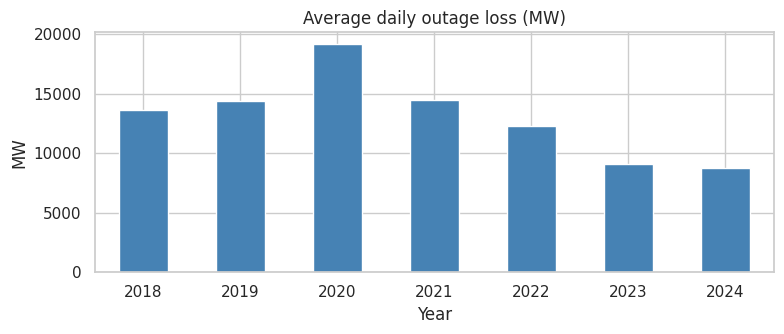

In [2]:
q = run('q01_yearly_trend'); display(q)
ax = q.plot.bar(x='Year', y='avg_daily_outage_mw', legend=False, color='steelblue', figsize=(8,3.5))
ax.set_title('Average daily outage loss (MW)'); ax.set_ylabel('MW'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

**Read-out:** average daily outage loss peaks in 2020 (about 19,200 MW) and falls to about 8,800 MW in 2024.

## 2. States
Share of outage loss and loss rate (outage MW-days as a share of monitored capacity-days).

In [3]:
display(run('q02_state_ranking'))

,state_name,outage_mw_days,share_of_outage_loss_pct,loss_rate_pct
0,Tamil Nadu,"11,478,393.0",36.0,24.4
1,Karnataka,"10,344,080.0",32.4,29.9
2,Andhra Pradesh,"7,643,740.0",24.0,17.0
3,Telangana,"2,415,925.0",7.6,9.7
4,Kerala,0.0,0.0,0.0
5,Lakshadweep,0.0,0.0,0.0
6,Puducherry,0.0,0.0,0.0


**Read-out:** Tamil Nadu has the largest share (36%), but Karnataka has the highest loss rate (29.9%). Kerala, Lakshadweep and Puducherry have no recorded outages; their loss is all shortfall.

## 3. What outage loss is made of

In [4]:
display(run('q03_loss_by_cause'))

,cause_category,outage_mw_days,share_pct
0,Technical (forced),"11,967,983.0",37.6
1,Demand / commercial (not scheduled),"10,989,058.0",34.5
2,Planned maintenance,"6,225,185.0",19.5
3,Fuel supply,"2,184,530.0",6.9
4,Financial / legal,"363,000.0",1.1
5,Not operational (new/unstabilised unit),"120,800.0",0.4


**Read-out:** only about 38% of outage loss is forced equipment trouble. About 34% is commercial (reserve shutdown or low schedule) and about 20% is planned maintenance.

## 4. Station concentration (window functions)

,station_rank,power_station,state_name,fuel_type,outage_mw_days,cumulative_share_pct
0,1,Kudgi Stpp,Karnataka,Coal/Lignite,"2,344,800.0",7.4
1,2,Yermarus Tpp,Karnataka,Coal/Lignite,"2,310,400.0",14.6
2,3,Raichur Tps,Karnataka,Coal/Lignite,"1,690,190.0",19.9
3,4,Bellary Tps,Karnataka,Coal/Lignite,"1,618,300.0",25.0
4,5,Muthiara Tpp,Tamil Nadu,Coal/Lignite,"1,603,200.0",30.0
5,6,Vizag Tpp,Andhra Pradesh,Coal/Lignite,"1,527,760.0",34.8
6,7,Udupi Tpp,Karnataka,Coal/Lignite,"1,483,800.0",39.5
7,8,Rayalaseema Tps,Andhra Pradesh,Coal/Lignite,"1,332,060.0",43.6
8,9,Kudankulam,Tamil Nadu,Nuclear,"1,296,000.0",47.7
9,10,North Chennai Tps,Tamil Nadu,Coal/Lignite,"1,285,320.0",51.7


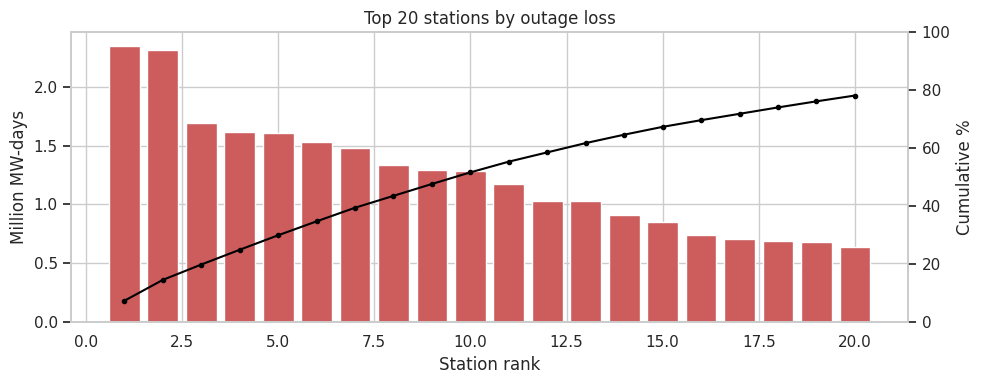

In [5]:
q = run('q04_station_pareto'); display(q)
fig, ax = plt.subplots(figsize=(10,4))
ax.bar(q.station_rank, q.outage_mw_days/1e6, color='indianred'); ax.set_ylabel('Million MW-days'); ax.set_xlabel('Station rank')
ax2 = ax.twinx(); ax2.plot(q.station_rank, q.cumulative_share_pct, color='black', marker='o', ms=3); ax2.set_ylim(0,100); ax2.set_ylabel('Cumulative %')
ax2.grid(False); ax.set_title('Top 20 stations by outage loss'); plt.tight_layout(); plt.show()

**Read-out:** the top 10 stations account for about 52% of outage loss and the top 20 for about 78%. Kudgi and Yermarus alone are about 15%.

## 5. Fuel: outage vs shortfall

In [6]:
display(run('q05_fuel_outage_vs_shortfall'))

,fuel_type,outage_mw_days,shortfall_mw_days,shortfall_share_pct
0,Coal/Lignite,"29,836,818.0","1,480,948.0",4.7
1,Nuclear,"2,045,320.0","4,300.0",0.2
2,Hydro,0.0,"5,952,217.0",100.0
3,Gas,0.0,"12,097,261.0",100.0
4,Diesel,0.0,"1,776.0",100.0


**Read-out:** gas, hydro and diesel show no recorded outages; all of their loss is shortfall. Coal/lignite carries about 94% of outage loss.

## 6. Median recovery time by cause

In [7]:
display(run('q06_median_recovery_by_cause'))

,cause,episodes,median_days
0,Financial / legal,4,113.5
1,Not operational (new/unstabilised unit),2,96.5
2,Planned maintenance,496,24.5
3,Fuel supply,295,5.0
4,Demand / commercial (not scheduled),1663,4.0
5,Technical (forced),5090,2.0
6,Not recorded,1972,0.0


**Read-out:** forced technical outages typically end in 2 days, planned maintenance takes about 24 days, and the few financial/legal cases last about 114 days. `Not recorded` rows are mostly sync-day-only records.

## 7. A few long outages carry most of the lost capacity

,duration_band,episodes,pct_of_episodes,pct_of_outage_mw_days
0,1: 0-2 days,5932,62.3,6.9
1,2: 3-7 days,1776,18.7,9.6
2,3: 8-30 days,1203,12.6,19.8
3,4: over 30 days,611,6.4,63.7


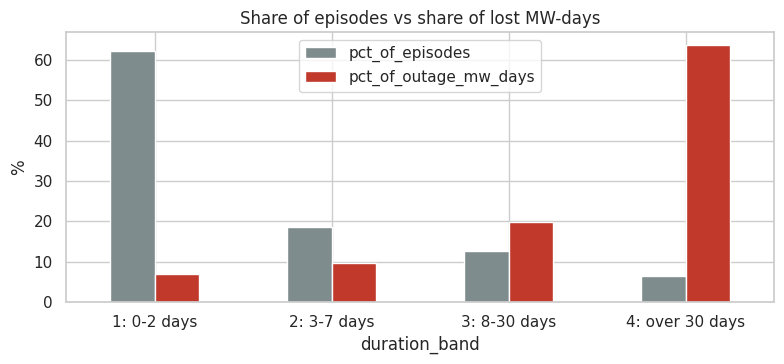

In [8]:
q = run('q07_long_outage_concentration'); display(q)
q.set_index('duration_band')[['pct_of_episodes','pct_of_outage_mw_days']].plot.bar(figsize=(8,3.8), color=['#7f8c8d','#c0392b'])
plt.title('Share of episodes vs share of lost MW-days'); plt.ylabel('%'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

**Read-out:** outages longer than 30 days are about 6% of episodes but about 64% of lost MW-days.

## 8. Repeat failures (LAG window function)

In [9]:
q = run('q08_repeat_failures'); display(q)

,unit,state,forced_episodes,repeats,repeat_pct
0,Neyveli Tps-Ii Exp | Unit 2,Tamil Nadu,104,94,90.4
1,Ramagundem-B Tps | Unit 1,Telangana,104,85,81.7
2,Neyveli Tps-Ii Exp | Unit 1,Tamil Nadu,96,85,88.5
3,Tuticorin Tps | Unit 2,Tamil Nadu,100,80,80.0
4,North Chennai Tps | Unit 3,Tamil Nadu,96,76,79.2
5,Raichur Tps | Unit 2,Karnataka,92,75,81.5
6,North Chennai Tps | Unit 1,Tamil Nadu,100,71,71.0
7,Tuticorin Tps | Unit 3,Tamil Nadu,92,68,73.9
8,North Chennai Tps | Unit 2,Tamil Nadu,91,67,73.6
9,Rayalaseema Tps | Unit 2,Andhra Pradesh,82,65,79.3


In [10]:
# Check the SQL against the Python result saved from notebook 02 (reports/tables/repeat_units.csv)
py = pd.read_csv('../reports/tables/repeat_units.csv').set_index('unit')
full = pd.read_sql(Q['q08_repeat_failures'].replace('LIMIT 15', ''), con).set_index('unit')
cmp = full.join(py[['forced_episodes','repeats']], rsuffix='_python')
print('Units compared:', len(cmp))
print('Forced episodes match:', (cmp.forced_episodes == cmp.forced_episodes_python).all())
print('Repeats match        :', (cmp.repeats == cmp.repeats_python).all(), f'(SQL total {cmp.repeats.sum():,} vs Python total {cmp.repeats_python.sum():,})')
print(f'Repeats / forced episodes: {cmp.repeats.sum() / cmp.forced_episodes.sum():.1%}')

Units compared: 151
Forced episodes match: True
Repeats match        : True (SQL total 2,827 vs Python total 2,827)
Repeats / forced episodes: 55.5%


**Read-out:** about 56% of forced trips start within 30 days of the same unit's previous outage ending (the dashboard card uses this definition; notebook 02 reports 57% because it divides by follow-on trips only). The worst units, such as Neyveli TPS-II Expansion, trip again within 30 days about 9 times in 10.

## 9. Seasonality

,0,1,2,3,4,5,6,7,8,9,10,11
month,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0
avg_daily_outage_mw,"12,338.0","10,561.0","9,345.0","8,710.0","10,412.0","13,651.0","15,623.0","16,185.0","14,152.0","13,906.0","14,917.0","14,558.0"


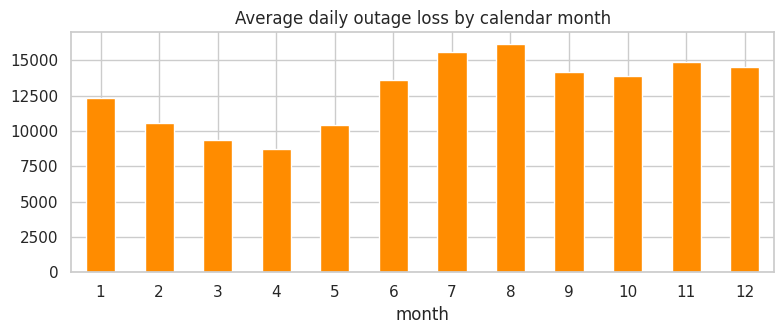

In [11]:
q = run('q09_seasonality'); display(q.T)
q.plot.bar(x='month', y='avg_daily_outage_mw', legend=False, color='darkorange', figsize=(8,3.5))
plt.title('Average daily outage loss by calendar month'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

**Read-out:** loss is lowest in March to April and highest in July to August. This pattern mixes all years, so it partly reflects when reserve shutdowns happened.

## 10. Data-quality checks

In [12]:
display(run('q10_data_quality'))
con.close(); os.remove(DB_PATH)

,check_name,value
0,duplicate unit-day keys,0
1,calendar days with no data,77
2,rows missing monitored_capacity,5943
3,rows where loss_mw > monitored_capacity,0
4,episodes still open at end of data,41


Every check passes except the known data gaps: 77 calendar days with no data and 5,943 rows without monitored capacity.